# Item-Based Collaborative Filtering - retail case study (notebook)
Offline pipeline (synthetic omnichannel data -> time-decayed implicit matrix -> BM25 cosine + shrinkage -> temporal split & grid search -> artifacts -> verification report -> charts) and the online scoring engine with guardrails and cold-start fallback, all run in-notebook. No API/server code here; see `api.py` for the service.

## 1. Imports & config

In [1]:
import hashlib
import json
import time
from pathlib import Path

%matplotlib inline
import matplotlib

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
import seaborn as sns  # noqa: E402
from scipy import sparse  # noqa: E402

try:
    import pyarrow  # noqa: F401
except ImportError as exc:  # pragma: no cover
    raise SystemExit("pyarrow is required: pip install -r requirements.txt") from exc

ROOT = Path.cwd()
OUT = ROOT / "output" / "notebook"   # separate from the API artifacts
ART = OUT / "artifacts"
CHARTS = OUT / "charts"

SEED = 42
N_USERS = 3000
N_DAYS = 180
START = pd.Timestamp("2025-01-01")
EVENT_W0 = {"view": 1.0, "add_to_cart": 3.0, "purchase": 5.0}
HALF_LIFE_DAYS = 30.0
LAMBDA = np.log(2) / HALF_LIFE_DAYS
BM25_K1, BM25_B = 1.2, 0.75
BETAS = [0, 5, 10, 25, 50, 100]
KS = [10, 20, 50, 100]
TOPN = 10
VAL_FRACTION = 0.2

CATEGORIES = ["Grocery", "Beverages", "Personal Care", "Home Care", "Electronics",
              "Apparel", "Footwear", "Toys", "Sports", "Books"]
CONSUMABLE_CATS = {"Grocery", "Beverages", "Personal Care", "Home Care"}
BASE_PRICE = {"Grocery": 4, "Beverages": 3, "Personal Care": 8, "Home Care": 9, "Electronics": 120,
              "Apparel": 35, "Footwear": 60, "Toys": 22, "Sports": 40, "Books": 15}

## 2. Synthetic data generator

In [2]:
def generate_data(rng: np.random.Generator):
    """Synthetic omnichannel retail data with category block structure + staple items."""
    rows, item_pop, is_staple = [], [], []
    n = 0
    for c_i, cat in enumerate(CATEGORIES):
        for s in range(3):
            sub = f"{cat}-S{s + 1}"
            ranks = rng.permutation(16) + 1
            for r in ranks:
                n += 1
                price = BASE_PRICE[cat] * rng.lognormal(0, 0.4)
                rows.append((f"SKU{n:04d}", cat, sub, round(price, 2), cat in CONSUMABLE_CATS,
                             bool(rng.random() > 0.08), rng.uniform(0.2, 0.5)))
                item_pop.append(float(r) ** -1.1)
                is_staple.append(False)
    # staples: bought by almost everybody, low margin, consumable
    for k, cat in enumerate(["Grocery", "Grocery", "Grocery", "Grocery", "Beverages", "Personal Care",
                             "Home Care", "Home Care"]):
        n += 1
        rows.append((f"SKU{n:04d}", cat, f"{cat}-S1", round(rng.uniform(1.5, 4), 2), True, True,
                     rng.uniform(0.04, 0.09)))
        item_pop.append(1.0)
        is_staple.append(True)
    catalog = pd.DataFrame(rows, columns=["item_id", "category", "sub_category", "price", "is_consumable",
                                          "in_stock", "margin_rate"])
    item_pop = np.array(item_pop)
    is_staple = np.array(is_staple)
    cat_arr = catalog["category"].to_numpy()
    sub_arr = catalog["sub_category"].to_numpy()
    items = catalog["item_id"].to_numpy()
    cat_items = {c: np.where((cat_arr == c) & ~is_staple)[0] for c in CATEGORIES}
    sub_items = {s: np.where((sub_arr == s) & ~is_staple)[0] for s in np.unique(sub_arr)}
    staple_idx = np.where(is_staple)[0]
    nonstaple = np.where(~is_staple)[0]
    gp = item_pop[nonstaple] / item_pop[nonstaple].sum()
    sp = item_pop[staple_idx] / item_pop[staple_idx].sum()

    ev_u, ev_i, ev_t, ev_type = [], [], [], []
    tr_u, tr_i, tr_t, tr_q, tr_c = [], [], [], [], []
    channels = np.array(["web", "app", "pos"])
    price = catalog["price"].to_numpy()
    margin = catalog["margin_rate"].to_numpy()
    for u in range(N_USERS):
        uid = f"U{u:05d}"
        n_cats = rng.choice([1, 2, 3], p=[0.4, 0.4, 0.2])
        cats = rng.choice(CATEGORIES, n_cats, replace=False)
        aff = rng.dirichlet(np.ones(n_cats) * 2)
        fav_sub = {c: f"{c}-S{rng.integers(1, 4)}" for c in cats}
        n_int = rng.poisson(40) + 5
        days = (N_DAYS - 1) * rng.beta(1.6, 1.0, n_int)
        for d in days:
            x = rng.random()
            if x < 0.12:
                it = rng.choice(staple_idx, p=sp)
            elif x < 0.18:
                it = rng.choice(nonstaple, p=gp)
            else:
                c = rng.choice(cats, p=aff)
                pool = sub_items[fav_sub[c]] if rng.random() < 0.6 else cat_items[c]
                w = item_pop[pool]
                it = rng.choice(pool, p=w / w.sum())
            t = START + pd.Timedelta(days=float(d))
            ev_u.append(uid); ev_i.append(items[it]); ev_t.append(t); ev_type.append("view")
            if rng.random() < 0.4:
                t2 = t + pd.Timedelta(minutes=float(rng.integers(1, 120)))
                ev_u.append(uid); ev_i.append(items[it]); ev_t.append(t2); ev_type.append("add_to_cart")
                if rng.random() < 0.6:
                    t3 = t2 + pd.Timedelta(minutes=float(rng.integers(1, 240)))
                    ev_u.append(uid); ev_i.append(items[it]); ev_t.append(t3); ev_type.append("purchase")
                    q = 1 + (rng.poisson(1.0) if is_staple[it] else 0)
                    tr_u.append(uid); tr_i.append(items[it]); tr_t.append(t3); tr_q.append(q)
                    tr_c.append(rng.choice(channels))
    events = pd.DataFrame({"user_id": ev_u, "item_id": ev_i, "event_type": ev_type, "timestamp": ev_t})
    tr = pd.DataFrame({"user_id": tr_u, "item_id": tr_i, "timestamp": tr_t, "quantity": tr_q, "channel": tr_c})
    rate = catalog.set_index("item_id")["margin_rate"]
    pr = catalog.set_index("item_id")["price"]
    tr["gross_margin"] = (tr["item_id"].map(pr) * tr["quantity"] * tr["item_id"].map(rate)).round(2)
    staple_ids = items[staple_idx].tolist()
    catalog_out = catalog.drop(columns=["margin_rate"])
    return tr, events, catalog_out, staple_ids

## 3. Time-decayed implicit feature matrix

In [3]:
def build_matrix(events, trans, user_idx, item_idx, t_ref, t_max, lam=LAMBDA):
    """Time-decayed implicit user x item matrix using events with t <= t_max (days)."""
    ev = events[(events["event_type"] != "purchase") & (events["t"] <= t_max)]
    w_ev = ev["event_type"].map(EVENT_W0).to_numpy() * np.exp(-lam * (t_ref - ev["t"].to_numpy()))
    tr = trans[trans["t"] <= t_max]
    w_tr = EVENT_W0["purchase"] * (1 + np.log(tr["quantity"].to_numpy())) * np.exp(-lam * (t_ref - tr["t"].to_numpy()))
    u = np.concatenate([ev["user_id"].map(user_idx).to_numpy(), tr["user_id"].map(user_idx).to_numpy()])
    i = np.concatenate([ev["item_id"].map(item_idx).to_numpy(), tr["item_id"].map(item_idx).to_numpy()])
    w = np.concatenate([w_ev, w_tr])
    return sparse.csr_matrix((w, (u, i)), shape=(len(user_idx), len(item_idx))).toarray()

## 4. BM25 cosine, shrinkage, top-K pruning

In [4]:
def bm25_cosine(X, k1=BM25_K1, b=BM25_B):
    """BM25-weighted item-item cosine + co-occurrence counts. Dense (fine for ~500 items;
    swap for sparse X.T @ X + chunked top-K at larger catalog sizes)."""
    B = (X > 0).astype(np.float32)
    n_users = X.shape[0]
    df = B.sum(0)
    idf = np.log1p((n_users - df + 0.5) / (df + 0.5))          # damps popular (staple) items
    ulen = X.sum(1)
    avg = ulen[ulen > 0].mean()
    denom = X + k1 * (1 - b + b * ulen / avg)[:, None]          # damps heavy users
    W = X * (k1 + 1) / np.where(denom == 0, 1, denom) * idf[None, :]
    W = W / np.maximum(np.linalg.norm(W, axis=0, keepdims=True), 1e-12)
    S = W.T @ W
    np.fill_diagonal(S, 0)
    nij = B.T @ B
    np.fill_diagonal(nij, 0)
    return S, nij


def shrink(S, nij, beta):
    return S * np.where(nij > 0, nij / (nij + beta + 1e-12), 0.0)


def prune_topk(S, k):
    out = np.zeros_like(S)
    idx = np.argpartition(-S, k - 1, axis=1)[:, :k]
    rows = np.arange(S.shape[0])[:, None]
    out[rows, idx] = S[rows, idx]
    return out

## 5. Metrics & helpers

In [5]:
def evaluate(scores, G, mask, n=TOPN):
    """NDCG@n, Recall@n, coverage. scores: users x items; G: binary truth; mask: bool (excluded)."""
    sc = np.where(mask, -np.inf, scores)
    top = np.argpartition(-sc, n - 1, axis=1)[:, :n]
    order = np.argsort(-np.take_along_axis(sc, top, 1), axis=1)
    top = np.take_along_axis(top, order, 1)
    hits = np.take_along_axis(G, top, 1)
    disc = 1 / np.log2(np.arange(n) + 2)
    dcg = (hits * disc).sum(1)
    nrel = G.sum(1)
    idcg = np.array([disc[: int(min(n, r))].sum() for r in nrel])
    recall = hits.sum(1) / np.maximum(nrel, 1)
    return {"ndcg": float((dcg / np.maximum(idcg, 1e-12)).mean()), "recall": float(recall.mean()),
            "coverage": float(len(np.unique(top)) / scores.shape[1])}


def neighbor_stats(S_topk, cat_arr, staple_mask):
    """Share of neighbor slots filled by staples and score-weighted intra-category share (non-staple seeds)."""
    nz = S_topk > 0
    seeds = ~staple_mask
    slots = nz[seeds].sum()
    staple_share = (nz[seeds][:, staple_mask].sum() / max(slots, 1))
    same = cat_arr[:, None] == cat_arr[None, :]
    intra = (S_topk * same)[seeds].sum() / max(S_topk[seeds].sum(), 1e-12)
    return float(staple_share), float(intra)


def sha(path: Path):
    return hashlib.sha256(path.read_bytes()).hexdigest()[:16]

## 6. Chart functions

In [6]:
def make_charts(events, trans, X, catalog, grid, best_beta, best_k, S_raw, nij, S_shr, cat_arr, staple_mask, report):
    # 01 sparsity / long tail
    fig, ax = plt.subplots(1, 3, figsize=(18, 5.2))
    freq = np.sort((X > 0).sum(0))[::-1]
    ax[0].loglog(np.arange(1, len(freq) + 1), freq, "o-", ms=3, color="#2a6fbb")
    ax[0].set(title="Item interaction frequency (long tail)", xlabel="item rank (log)", ylabel="# users (log)")
    ufreq = (X > 0).sum(1)
    sns.histplot(ufreq, bins=40, ax=ax[1], color="#2a9d8f")
    ax[1].set(title="Distinct items per user", xlabel="items", ylabel="users")
    order_i = np.argsort(-(X > 0).sum(0))[:120]
    order_u = np.argsort(-(X > 0).sum(1))[:120]
    sns.heatmap((X[np.ix_(order_u, order_i)] > 0).astype(int), cmap="Blues", cbar=False, ax=ax[2],
                xticklabels=False, yticklabels=False)
    dens = (X > 0).mean()
    ax[2].set(title=f"Top-120x120 interaction map | full matrix {X.shape[0]}x{X.shape[1]}, sparsity {100 * (1 - dens):.2f}%",
              xlabel="items (by popularity)", ylabel="users (by activity)")
    fig.tight_layout(); fig.savefig(CHARTS / "01_data_sparsity_and_long_tail.png", dpi=200); plt.close(fig)

    # 02 funnel + decay
    fig, ax = plt.subplots(1, 2, figsize=(15, 5.2))
    counts = events["event_type"].value_counts().reindex(["view", "add_to_cart", "purchase"])
    bars = ax[0].barh(counts.index[::-1], counts.values[::-1], color=["#e76f51", "#f4a261", "#2a6fbb"])
    for b, v, nm in zip(bars, counts.values[::-1], counts.index[::-1]):
        pct = 100 * v / counts.iloc[0]
        ax[0].text(v, b.get_y() + b.get_height() / 2, f" {v:,} ({pct:.0f}% of views)", va="center")
    ax[0].set(title="Event funnel: view -> add_to_cart -> purchase", xlabel="events", xlim=(0, counts.max() * 1.3))
    d = np.arange(0, 121)
    for nm, w0 in EVENT_W0.items():
        ax[1].plot(d, w0 * np.exp(-LAMBDA * d), label=f"{nm} (w0={w0:g})", lw=2)
    ax[1].axvline(HALF_LIFE_DAYS, color="gray", ls="--"); ax[1].text(HALF_LIFE_DAYS + 1, 4.5, f"half-life {HALF_LIFE_DAYS:g}d")
    ax[1].set(title=r"Exponential time decay $w(t)=w_0 e^{-\lambda \Delta t}$", xlabel="age (days)", ylabel="weight")
    ax[1].legend()
    fig.tight_layout(); fig.savefig(CHARTS / "02_feature_time_decay_and_funnel.png", dpi=200); plt.close(fig)

    # 03 tuning curves
    g = pd.DataFrame(grid)
    fig, ax = plt.subplots(1, 3, figsize=(18, 5.2))
    for a, (col, title) in zip(ax, [("ndcg", "Validation NDCG@10"), ("recall", "Validation Recall@10"), ("coverage", "Catalog coverage")]):
        for k, sub in g.groupby("K"):
            a.plot(sub["beta"], sub[col], "o-", label=f"K={k}")
        row = g[(g.beta == best_beta) & (g.K == best_k)].iloc[0]
        a.scatter([best_beta], [row[col]], marker="*", s=380, color="gold", edgecolor="k", zorder=5, label="selected")
        a.set(title=title, xlabel=r"shrinkage $\beta$", ylabel=col)
        a.legend(fontsize=8)
    fig.suptitle(f"Hyperparameter tuning (selected beta={best_beta}, K={best_k})")
    fig.tight_layout(); fig.savefig(CHARTS / "03_tuning_and_validation_curves.png", dpi=200); plt.close(fig)

    # 04 verification heatmaps
    order = np.argsort(cat_arr, kind="stable")
    bounds = np.cumsum([np.sum(cat_arr == c) for c in CATEGORIES])[:-1]
    fig, ax = plt.subplots(1, 3, figsize=(21, 6.2), gridspec_kw={"width_ratios": [1, 1, 0.8]})
    for a, M, title, cm in [(ax[0], np.log1p(nij), "Raw co-occurrence (log1p) - staples bleed across blocks", "mako_r"),
                             (ax[1], S_shr, "BM25 cosine + shrinkage - block-diagonal", "rocket_r")]:
        sns.heatmap(M[np.ix_(order, order)], ax=a, cmap=cm, xticklabels=False, yticklabels=False, cbar=True,
                    vmax=np.quantile(M, 0.995))
        for bnd in bounds:
            a.axhline(bnd, color="w", lw=0.6); a.axvline(bnd, color="w", lw=0.6)
        a.set_title(title, fontsize=11)
    q = report["neighbor_quality"]
    labels = ["staple slot share", "intra-category share"]
    x = np.arange(2); w = 0.35
    ax[2].bar(x - w / 2, [q["raw_cooccurrence"]["staple_slot_share"], q["raw_cooccurrence"]["intra_category_score_share"]], w, label="raw co-occurrence", color="#e76f51")
    ax[2].bar(x + w / 2, [q["final"]["staple_slot_share"], q["final"]["intra_category_score_share"]], w, label="BM25 + shrinkage", color="#2a6fbb")
    ax[2].set_xticks(x, labels); ax[2].set_ylim(0, 1); ax[2].legend()
    ax[2].set_title("Staple-bias removal & category purity (top-K neighbors)", fontsize=11)
    fig.tight_layout(); fig.savefig(CHARTS / "04_model_verification_similarity_heatmap.png", dpi=200); plt.close(fig)

## 7. Run the pipeline (same step code as `train_pipeline.py`)

In [7]:
t0 = time.time()
rng = np.random.default_rng(SEED)
for d in (ART, CHARTS):
    d.mkdir(parents=True, exist_ok=True)

### Generate data

In [8]:
print("[1/6] Generating synthetic omnichannel data ...")
trans, events, catalog, staple_ids = generate_data(rng)
for df in (trans, events):
    df["t"] = (df["timestamp"] - START).dt.total_seconds() / 86400.0
item_ids = catalog["item_id"].tolist()
item_idx = {k: i for i, k in enumerate(item_ids)}
user_ids = sorted(events["user_id"].unique())
user_idx = {k: i for i, k in enumerate(user_ids)}
n_items = len(item_ids)
cat_arr = catalog["category"].to_numpy()
staple_mask = np.isin(item_ids, staple_ids)
consumable = catalog["is_consumable"].to_numpy()
print(f"      users={len(user_ids)} items={n_items} events={len(events)} transactions={len(trans)}")

[1/6] Generating synthetic omnichannel data ...


      users=3000 items=488 events=221595 transactions=32336


### Temporal split + hyperparameter grid search

In [9]:
print("[2/6] Temporal split + hyperparameter grid search ...")
split_day = N_DAYS * (1 - VAL_FRACTION)
X_tr = build_matrix(events, trans, user_idx, item_idx, t_ref=split_day, t_max=split_day)
val_tr = trans[trans["t"] > split_day]
train_tr = trans[trans["t"] <= split_day]
assert train_tr["t"].max() <= split_day < val_tr["t"].min(), "temporal leakage"
G = np.zeros((len(user_ids), n_items), dtype=np.float32)
G[val_tr["user_id"].map(user_idx).to_numpy(), val_tr["item_id"].map(item_idx).to_numpy()] = 1
P = np.zeros_like(G)
P[train_tr["user_id"].map(user_idx).to_numpy(), train_tr["item_id"].map(item_idx).to_numpy()] = 1
mask = (P > 0) & (~consumable[None, :])        # durable repeat suppression
G = G * (~mask)                                # cannot recommend -> not ground truth
keep = (G.sum(1) > 0) & (X_tr.sum(1) > 0)
Xe, Ge, maske = X_tr[keep], G[keep], mask[keep]
print(f"      eval users={int(keep.sum())}")

S_raw, nij = bm25_cosine(X_tr)
grid = []
for beta in BETAS:
    Ss = shrink(S_raw, nij, beta)
    for k in KS:
        m = evaluate(Xe @ prune_topk(Ss, k), Ge, maske)
        grid.append({"beta": beta, "K": k, **m})
        print(f"      beta={beta:>3} K={k:>3} ndcg={m['ndcg']:.4f} recall={m['recall']:.4f} cov={m['coverage']:.3f}")
gdf = pd.DataFrame(grid).sort_values(["ndcg", "recall"], ascending=False)
best = gdf.iloc[0].to_dict()
best_beta, best_k = int(best["beta"]), int(best["K"])
print(f"      best: beta={best_beta} K={best_k} ndcg={best['ndcg']:.4f} recall={best['recall']:.4f}")

# baselines on the same split
pop = np.asarray(P.sum(0))
pop_m = evaluate(np.tile(pop, (Xe.shape[0], 1)).astype(float), Ge, maske)
cooc_k = prune_topk(nij.astype(float), best_k)
raw_m = evaluate(Xe @ cooc_k, Ge, maske)

[2/6] Temporal split + hyperparameter grid search ...
      eval users=2777


      beta=  0 K= 10 ndcg=0.2725 recall=0.3722 cov=0.738
      beta=  0 K= 20 ndcg=0.2679 recall=0.3680 cov=0.754
      beta=  0 K= 50 ndcg=0.2664 recall=0.3653 cov=0.717
      beta=  0 K=100 ndcg=0.2690 recall=0.3693 cov=0.709
      beta=  5 K= 10 ndcg=0.2731 recall=0.3746 cov=0.682
      beta=  5 K= 20 ndcg=0.2691 recall=0.3713 cov=0.684
      beta=  5 K= 50 ndcg=0.2668 recall=0.3673 cov=0.643
      beta=  5 K=100 ndcg=0.2678 recall=0.3674 cov=0.633
      beta= 10 K= 10 ndcg=0.2720 recall=0.3743 cov=0.629


      beta= 10 K= 20 ndcg=0.2687 recall=0.3714 cov=0.641
      beta= 10 K= 50 ndcg=0.2666 recall=0.3688 cov=0.615
      beta= 10 K=100 ndcg=0.2674 recall=0.3696 cov=0.600
      beta= 25 K= 10 ndcg=0.2699 recall=0.3728 cov=0.564
      beta= 25 K= 20 ndcg=0.2678 recall=0.3701 cov=0.584
      beta= 25 K= 50 ndcg=0.2631 recall=0.3635 cov=0.564
      beta= 25 K=100 ndcg=0.2653 recall=0.3672 cov=0.553
      beta= 50 K= 10 ndcg=0.2677 recall=0.3728 cov=0.525
      beta= 50 K= 20 ndcg=0.2659 recall=0.3691 cov=0.557


      beta= 50 K= 50 ndcg=0.2599 recall=0.3602 cov=0.518
      beta= 50 K=100 ndcg=0.2641 recall=0.3658 cov=0.516
      beta=100 K= 10 ndcg=0.2616 recall=0.3677 cov=0.494
      beta=100 K= 20 ndcg=0.2612 recall=0.3652 cov=0.504
      beta=100 K= 50 ndcg=0.2544 recall=0.3554 cov=0.484
      beta=100 K=100 ndcg=0.2577 recall=0.3585 cov=0.486
      best: beta=5 K=10 ndcg=0.2731 recall=0.3746


### Refit on full data + write artifacts

In [10]:
print("[3/6] Refitting on full data + writing artifacts ...")
t_end = float(max(events["t"].max(), trans["t"].max()))
X_full = build_matrix(events, trans, user_idx, item_idx, t_ref=t_end, t_max=t_end)
S_full_raw, nij_full = bm25_cosine(X_full)
S_full = shrink(S_full_raw, nij_full, best_beta)
S_top = prune_topk(S_full, best_k)
rows = []
for i in range(n_items):
    nb = np.where(S_top[i] > 0)[0]
    nb = nb[np.argsort(-S_top[i, nb])]
    rows += [(item_ids[i], item_ids[j], float(S_top[i, j]), r + 1) for r, j in enumerate(nb)]
sim_df = pd.DataFrame(rows, columns=["item_id", "neighbor_id", "score", "rank"])
sim_df.to_parquet(ART / "item_sim_map.parquet", index=False)
catalog.to_parquet(ART / "catalog.parquet", index=False)

# user history: top decayed items + purchase recency (for durable / consumable suppression)
lp = trans.groupby(["user_id", "item_id"]).agg(n_purchases=("quantity", "size"), last_purchase_ts=("timestamp", "max")).reset_index()
hist = []
for u_i, uid in enumerate(user_ids):
    row = X_full[u_i]
    top = np.argsort(-row)[:50]
    top = top[row[top] > 0]
    hist += [(uid, item_ids[j], float(row[j])) for j in top]
hist_df = pd.DataFrame(hist, columns=["user_id", "item_id", "score"])
hist_df = hist_df.merge(lp, on=["user_id", "item_id"], how="outer")
hist_df["score"] = hist_df["score"].fillna(0.0)
hist_df["n_purchases"] = hist_df["n_purchases"].fillna(0).astype(int)
hist_df.to_parquet(ART / "user_history.parquet", index=False)

tr_full = trans.copy()
tr_full["w"] = np.exp(-LAMBDA * (t_end - tr_full["t"])) * tr_full["gross_margin"]
fb = tr_full.groupby("item_id")["w"].sum().sort_values(ascending=False)
cat_i = catalog.set_index("item_id")
fallback = [{"item_id": i, "score": round(float(s), 4), "category": cat_i.loc[i, "category"],
             "sub_category": cat_i.loc[i, "sub_category"]} for i, s in fb.items()]
(ART / "fallback_popular.json").write_text(json.dumps(fallback, indent=1))

version = "ibcf-" + hashlib.sha256(sim_df.to_csv(index=False).encode()).hexdigest()[:8]
meta = {"model_version": version, "reference_time": (START + pd.Timedelta(days=t_end)).isoformat(),
        "beta": best_beta, "K": best_k, "half_life_days": HALF_LIFE_DAYS, "staple_item_ids": staple_ids,
        "consumable_repurchase_days": 14, "n_items": n_items, "n_users": len(user_ids)}
(ART / "model_meta.json").write_text(json.dumps(meta, indent=1))

[3/6] Refitting on full data + writing artifacts ...


335

### Verification report

In [11]:
print("[4/6] Verification report ...")
s_final_stats = neighbor_stats(prune_topk(shrink(S_raw, nij, best_beta), best_k), cat_arr, staple_mask)
s_raw_stats = neighbor_stats(cooc_k, cat_arr, staple_mask)
checks = {
    "no_temporal_leakage": bool(train_tr["t"].max() <= split_day < val_tr["t"].min()),
    "beats_popularity_ndcg": bool(best["ndcg"] > pop_m["ndcg"]),
    "beats_raw_cooccurrence_ndcg": bool(best["ndcg"] > raw_m["ndcg"]),
    "intra_category_share_gt_0.5": bool(s_final_stats[1] > 0.5),
    "staple_bias_reduced_vs_raw": bool(s_final_stats[0] < s_raw_stats[0]),
    "every_item_has_neighbors": bool(sim_df["item_id"].nunique() == n_items),
}
report = {
    "model_version": version, "generated_at": pd.Timestamp.now().isoformat(),
    "best_params": {"beta": best_beta, "K": best_k},
    "validation_metrics": {"ndcg@10": best["ndcg"], "recall@10": best["recall"], "coverage": best["coverage"]},
    "baselines": {"popularity": pop_m, "raw_cooccurrence_topK": raw_m},
    "neighbor_quality": {
        "final": {"staple_slot_share": s_final_stats[0], "intra_category_score_share": s_final_stats[1]},
        "raw_cooccurrence": {"staple_slot_share": s_raw_stats[0], "intra_category_score_share": s_raw_stats[1]}},
    "split": {"split_day": split_day, "train_max_day": float(train_tr["t"].max()), "val_min_day": float(val_tr["t"].min()),
              "eval_users": int(keep.sum())},
    "grid": grid, "checks": checks, "all_checks_passed": bool(all(checks.values())),
    "artifacts": {p.name: sha(p) for p in sorted(ART.glob("*")) if p.name != "verification_report.json"},
}
(ART / "verification_report.json").write_text(json.dumps(report, indent=1))
print("      checks:", checks)

[4/6] Verification report ...
      checks: {'no_temporal_leakage': True, 'beats_popularity_ndcg': True, 'beats_raw_cooccurrence_ndcg': True, 'intra_category_share_gt_0.5': True, 'staple_bias_reduced_vs_raw': True, 'every_item_has_neighbors': True}


### Charts

In [12]:
print("[5/6] Charts ...")
sns.set_theme(style="whitegrid", context="notebook")
make_charts(events, trans, X_full, catalog, grid, best_beta, best_k, S_full_raw, nij_full, S_full,
            cat_arr, staple_mask, report)
print(f"[6/6] Done in {time.time() - t0:.1f}s -> {OUT}")

[5/6] Charts ...


[6/6] Done in 14.0s -> D:\Ramakrishna_D\Python\GitProjects\machinelearning\recommenders\ItemBasedCF\output\notebook


## 8. Generated charts

01_data_sparsity_and_long_tail.png


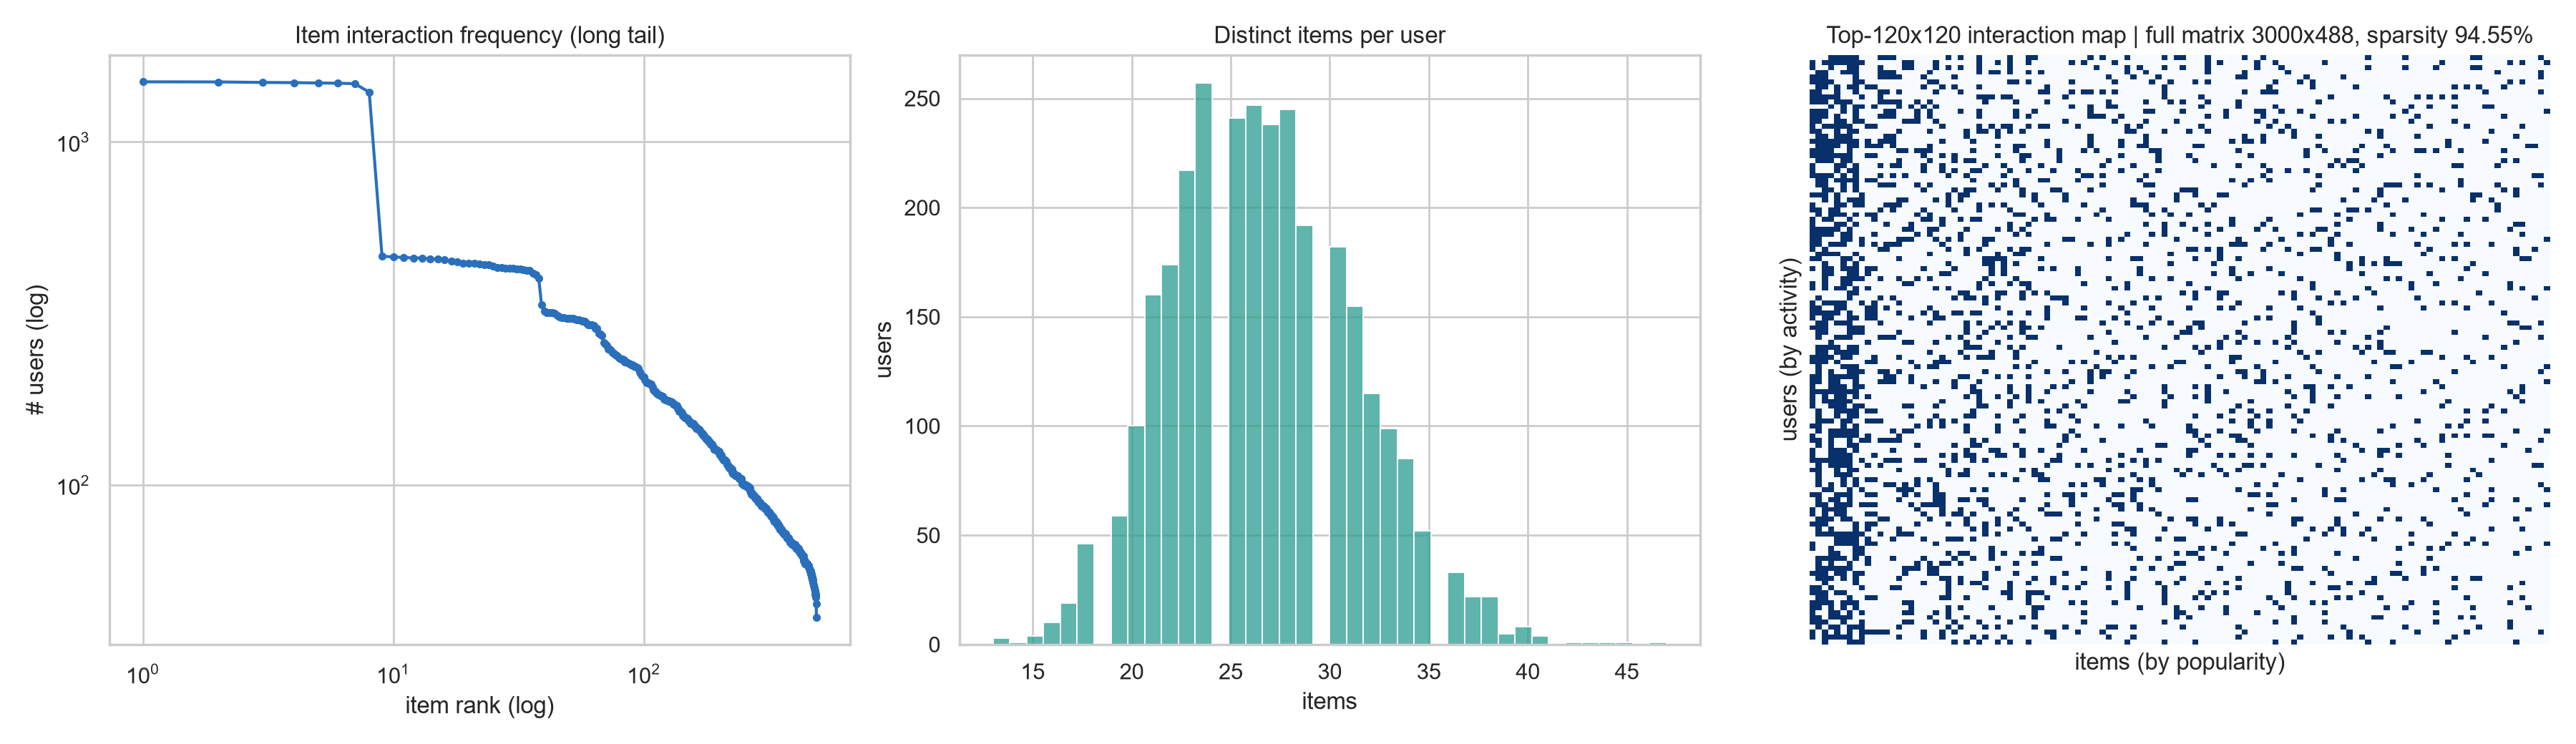

02_feature_time_decay_and_funnel.png


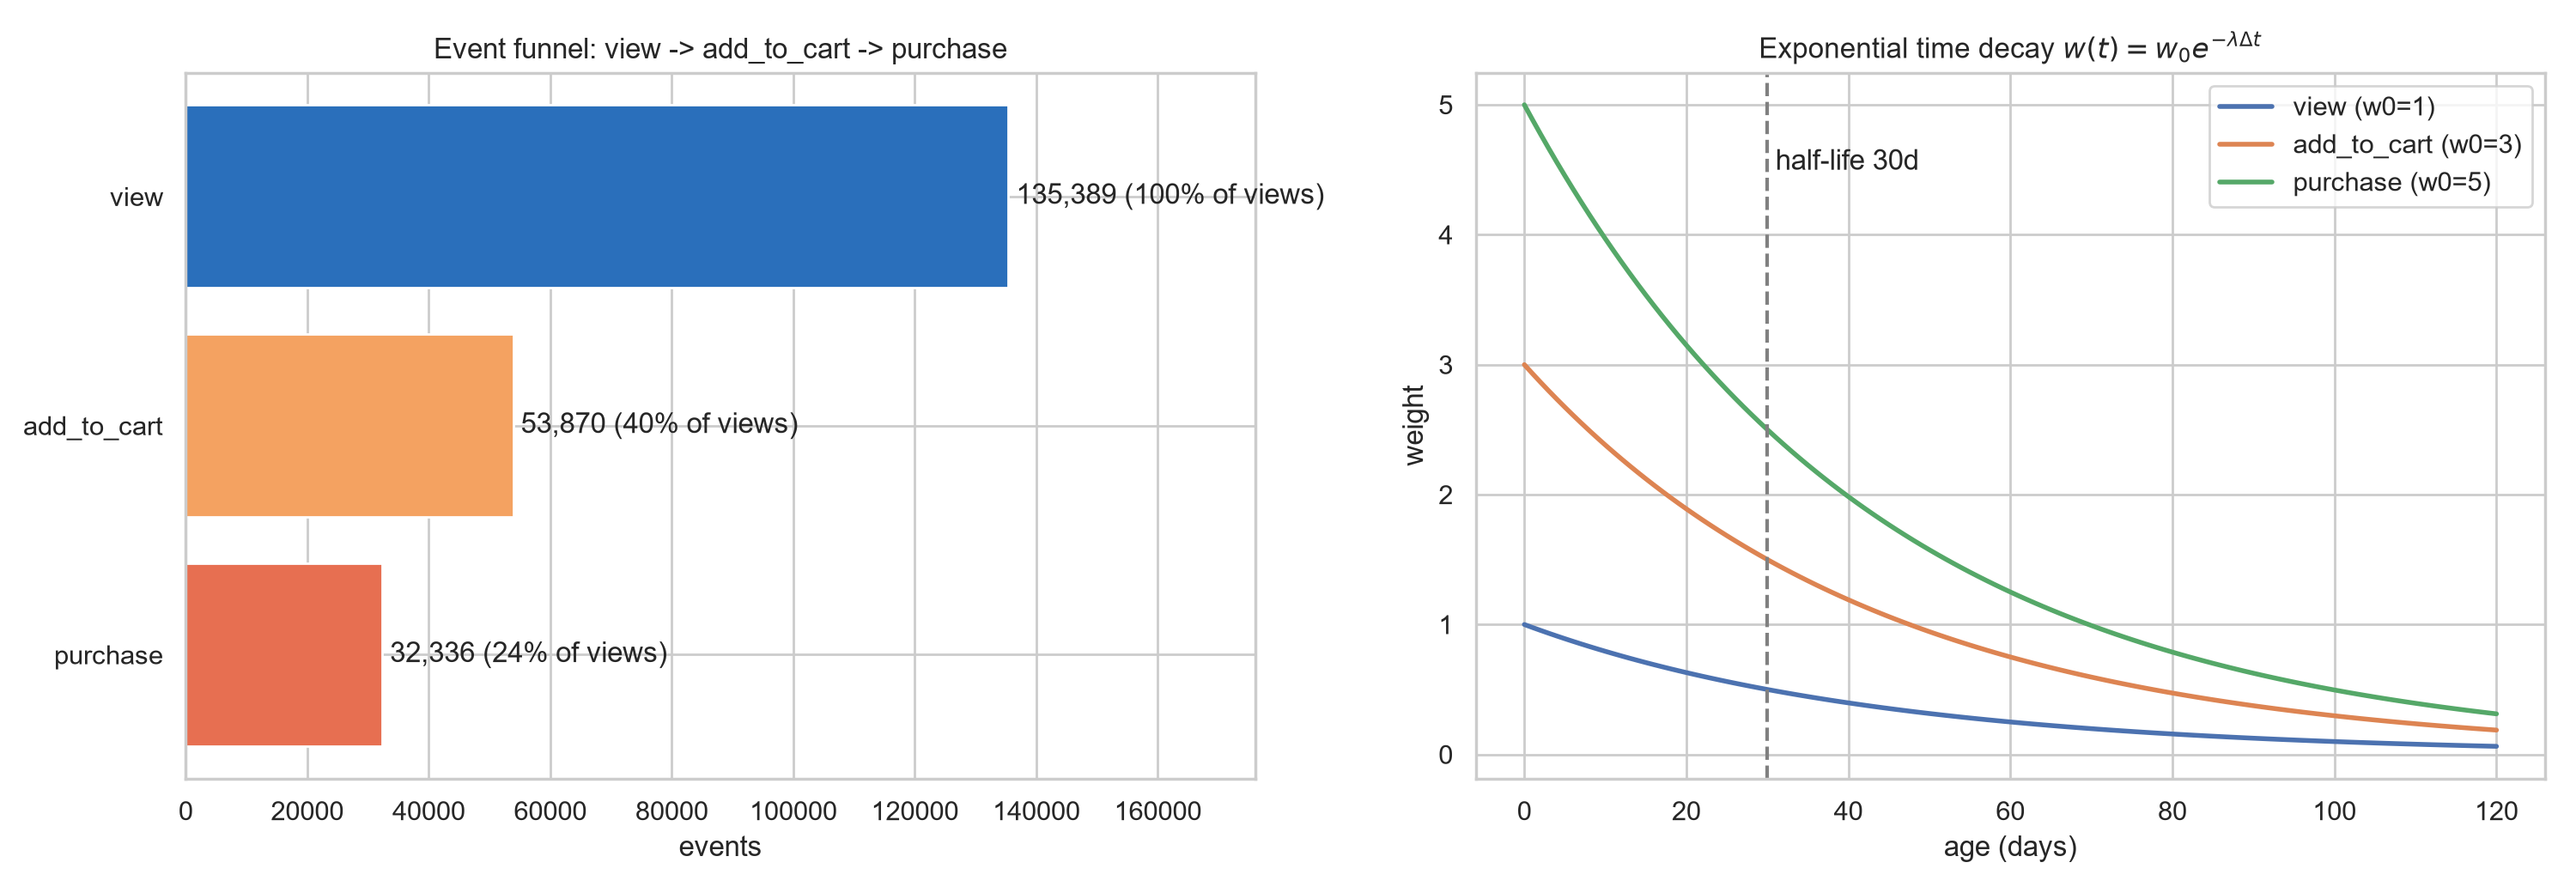

03_tuning_and_validation_curves.png


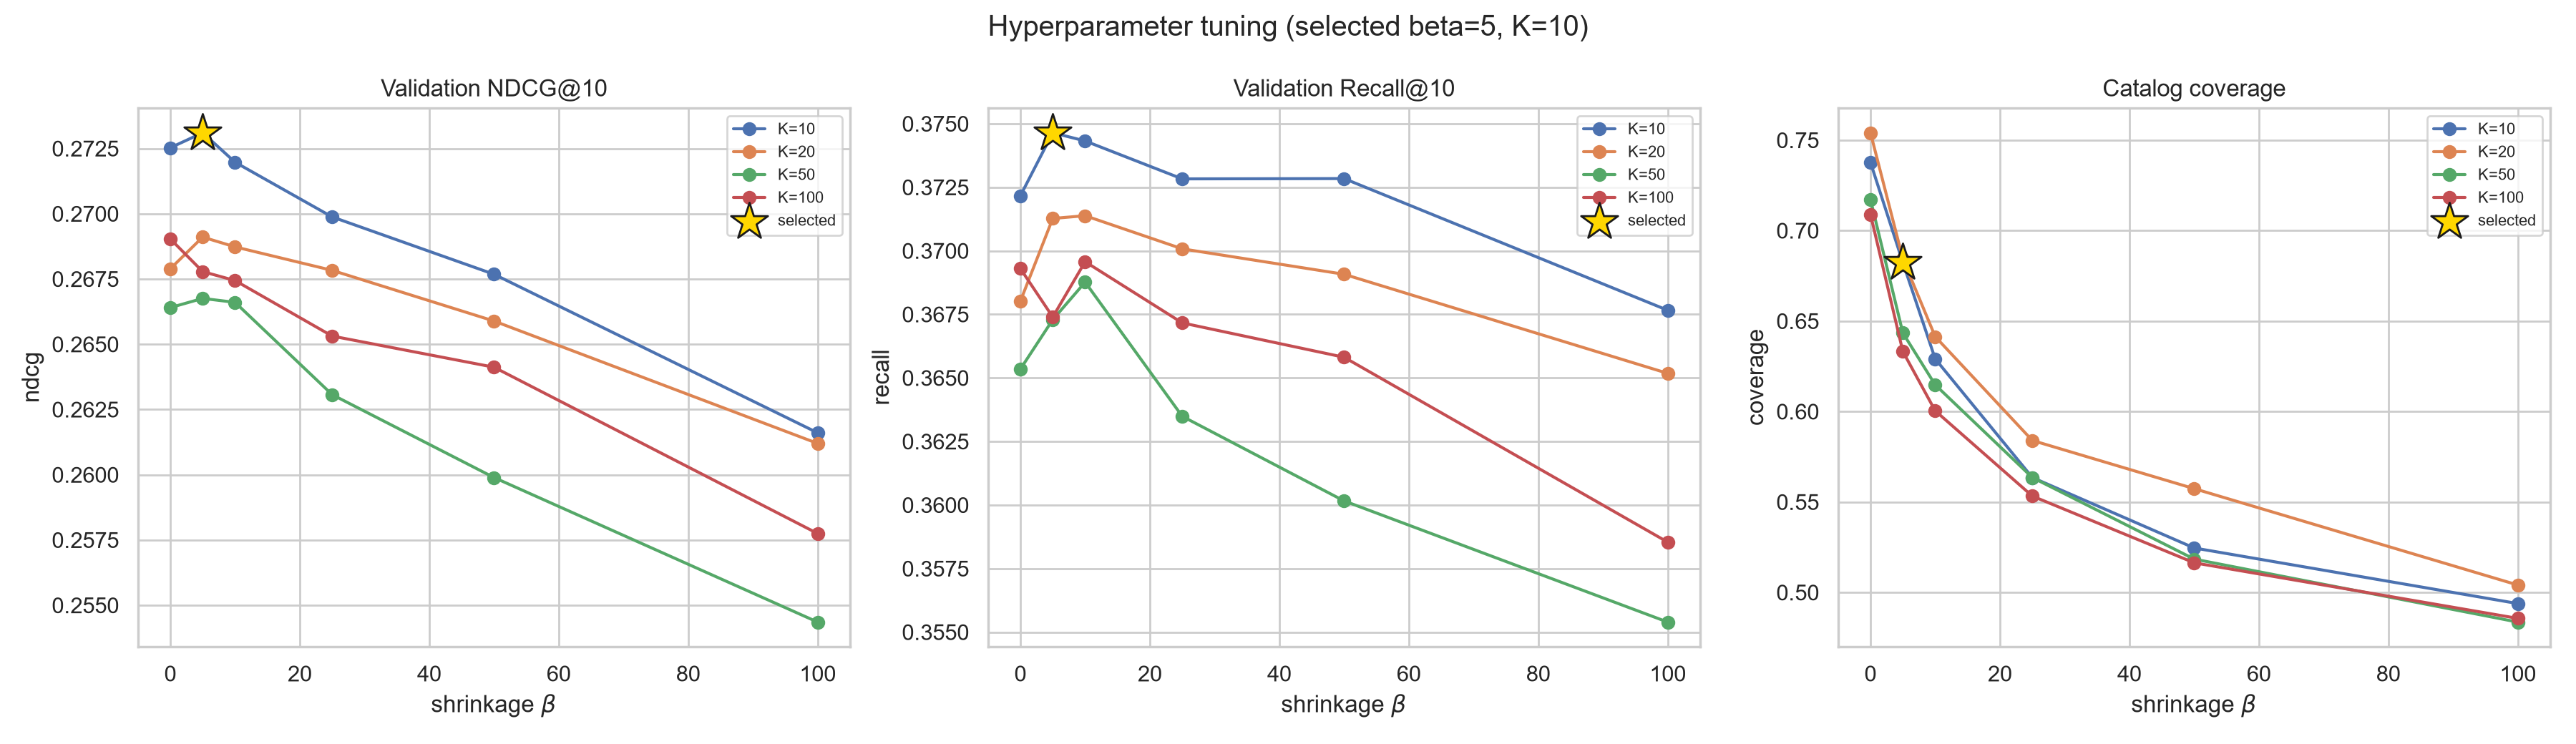

04_model_verification_similarity_heatmap.png


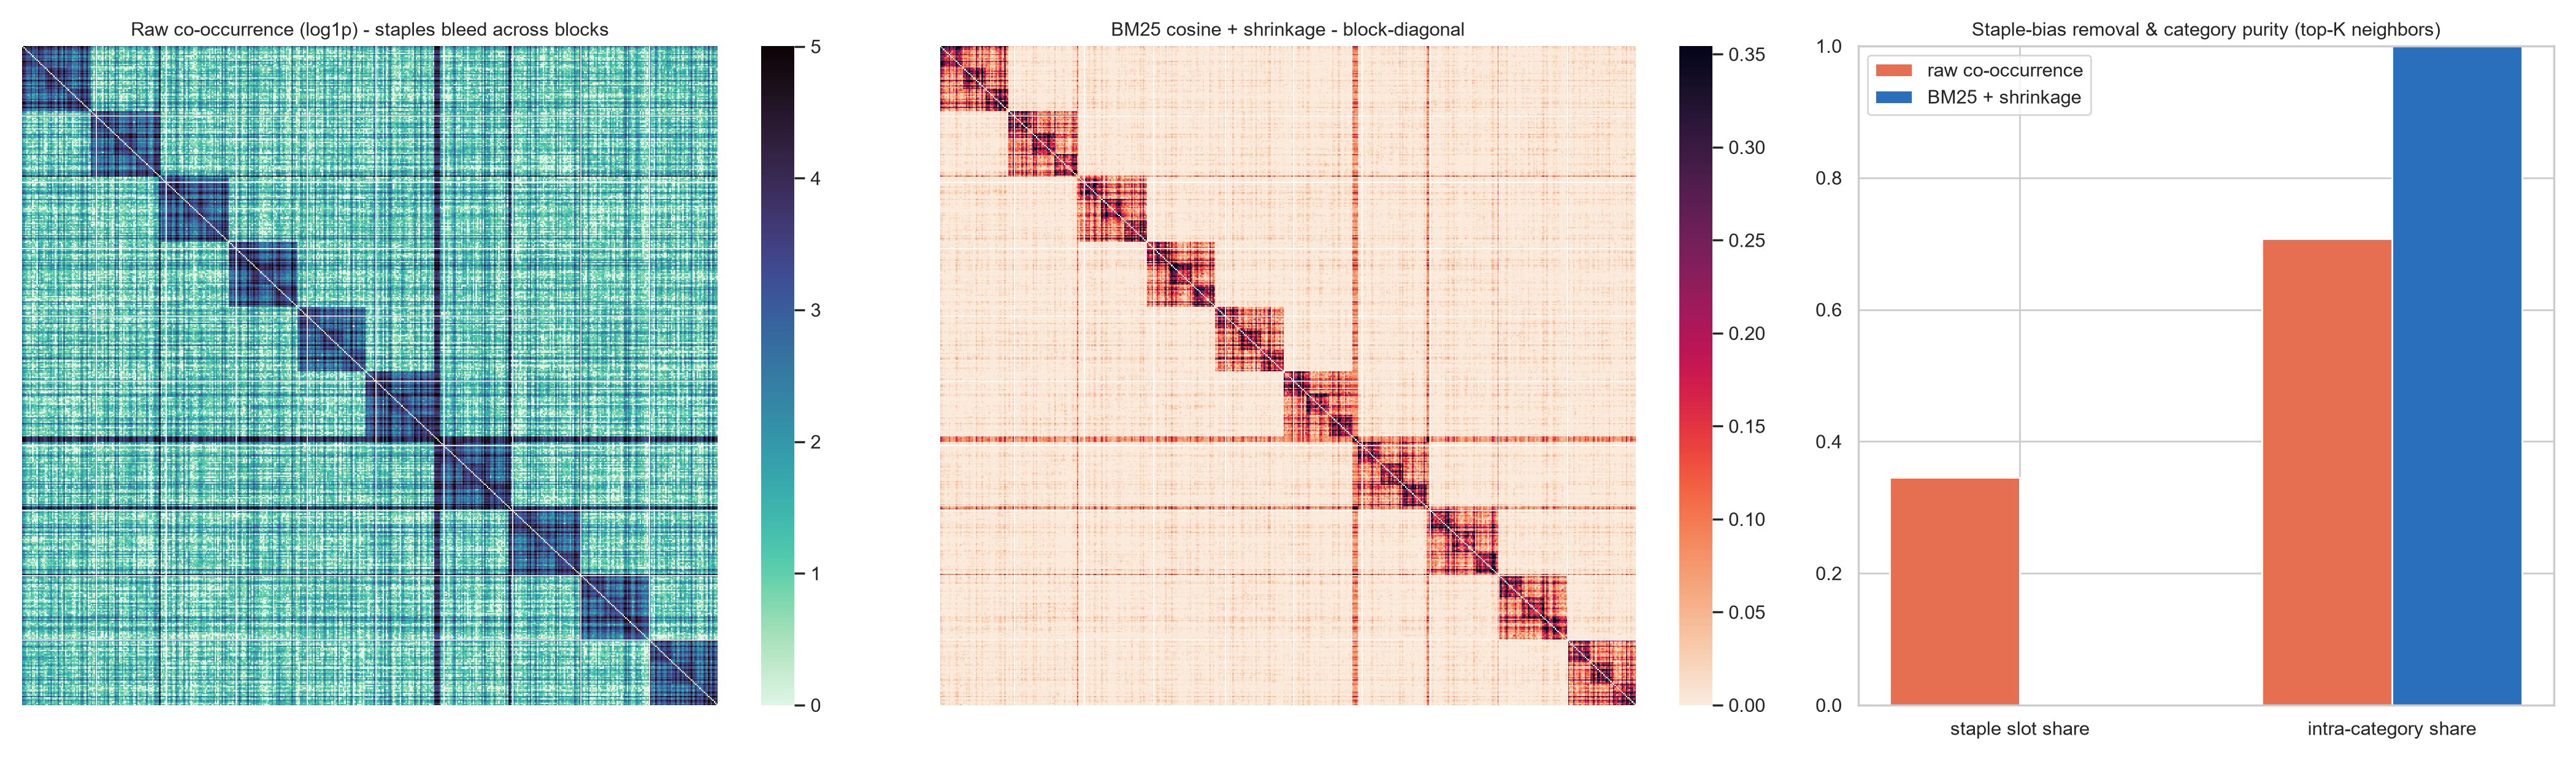

In [13]:
from IPython.display import Image, display
for p in sorted(CHARTS.glob("*.png")):
    print(p.name); display(Image(filename=str(p), width=1100))

## 9. Verification report

In [14]:
import json
rep = json.loads((ART/"verification_report.json").read_text())
print(json.dumps({k: rep[k] for k in ["model_version","best_params","validation_metrics","baselines","neighbor_quality","checks","all_checks_passed"]}, indent=1))
assert rep["all_checks_passed"]

{
 "model_version": "ibcf-ca75a092",
 "best_params": {
  "beta": 5,
  "K": 10
 },
 "validation_metrics": {
  "ndcg@10": 0.27310410570623517,
  "recall@10": 0.3746451735496521,
  "coverage": 0.6823770491803278
 },
 "baselines": {
  "popularity": {
   "ndcg": 0.10387731516540452,
   "recall": 0.16130059957504272,
   "coverage": 0.020491803278688523
  },
  "raw_cooccurrence_topK": {
   "ndcg": 0.1593536220236958,
   "recall": 0.274873822927475,
   "coverage": 0.21721311475409835
  }
 },
 "neighbor_quality": {
  "final": {
   "staple_slot_share": 0.0,
   "intra_category_score_share": 1.0
  },
  "raw_cooccurrence": {
   "staple_slot_share": 0.345,
   "intra_category_score_share": 0.7072887418746875
  }
 },
 "checks": {
  "no_temporal_leakage": true,
  "beats_popularity_ndcg": true,
  "beats_raw_cooccurrence_ndcg": true,
  "intra_category_share_gt_0.5": true,
  "staple_bias_reduced_vs_raw": true,
  "every_item_has_neighbors": true
 },
 "all_checks_passed": true
}


## 10. Online inference engine (loads the artifacts; guardrails + fallback)

In [15]:
SESSION_BOOST = 2.0
MAX_PER_SUBCATEGORY = 3
MAX_CANDIDATES = 500


class RecommenderEngine:
    def __init__(self) -> None:
        self.loaded = False

    # ------------------------------------------------------------------ loading
    def load(self, artifact_dir: str | Path) -> "RecommenderEngine":
        d = Path(artifact_dir)
        meta = json.loads((d / "model_meta.json").read_text())
        catalog = pd.read_parquet(d / "catalog.parquet")
        sim = pd.read_parquet(d / "item_sim_map.parquet")
        hist = pd.read_parquet(d / "user_history.parquet")
        fallback = json.loads((d / "fallback_popular.json").read_text())

        self.meta = meta
        self.version: str = meta["model_version"]
        self.items: list[str] = catalog["item_id"].tolist()
        self.idx = {k: i for i, k in enumerate(self.items)}
        self.category = catalog["category"].to_numpy()
        self.sub_category = catalog["sub_category"].to_numpy()
        self.price = catalog["price"].to_numpy()
        self.consumable = catalog["is_consumable"].to_numpy(dtype=bool)
        self.in_stock = catalog["in_stock"].to_numpy(dtype=bool)
        n = len(self.items)

        self.neighbors: list[tuple[np.ndarray, np.ndarray]] = [(np.empty(0, int), np.empty(0))] * n
        sim = sim.assign(i=sim["item_id"].map(self.idx), j=sim["neighbor_id"].map(self.idx))
        for i, g in sim.groupby("i"):
            g = g.sort_values("rank")
            self.neighbors[int(i)] = (g["j"].to_numpy(int), g["score"].to_numpy(float))

        self.ref_ts = pd.Timestamp(meta["reference_time"])
        self.repurchase_s = meta.get("consumable_repurchase_days", 14) * 86400
        self.history: dict[str, dict] = {}
        hist = hist.assign(j=hist["item_id"].map(self.idx))
        mx = hist.groupby("user_id")["score"].transform("max").replace(0, 1)
        hist["w"] = hist["score"] / mx
        for uid, g in hist.groupby("user_id"):
            seeds = g[g["w"] > 0]
            purchased = g[g["n_purchases"] > 0]
            last = {int(j): (self.ref_ts - ts).total_seconds() for j, ts in zip(purchased["j"], purchased["last_purchase_ts"])}
            self.history[uid] = {"seed_idx": seeds["j"].to_numpy(int), "seed_w": seeds["w"].to_numpy(float),
                                 "purchased_age_s": last}
        self.fallback = [(self.idx[f["item_id"]], f["score"]) for f in fallback if f["item_id"] in self.idx]
        covered = set()
        for nb, _ in self.neighbors:
            covered.update(nb.tolist())
        self.catalog_coverage = len(covered) / n
        self.loaded = True
        return self

    def status(self) -> dict:
        return {"loaded": self.loaded, "model_version": getattr(self, "version", None),
                "n_items": len(self.items) if self.loaded else 0,
                "n_users": len(self.history) if self.loaded else 0,
                "catalog_coverage": round(self.catalog_coverage, 4) if self.loaded else 0.0,
                "params": {"beta": self.meta.get("beta"), "K": self.meta.get("K")} if self.loaded else {}}

    # --------------------------------------------------------------- guardrails
    def _suppressed(self, user_hist: dict | None) -> set[int]:
        """Durable items already purchased are never re-recommended; consumables are allowed
        again after the replenishment window."""
        out: set[int] = set()
        if not user_hist:
            return out
        for j, age in user_hist["purchased_age_s"].items():
            if (not self.consumable[j]) or age < self.repurchase_s:
                out.add(j)
        return out

    def _select(self, ranked, limit, blocked, in_stock_only, reasons, strategy_reason):
        per_sub: dict[str, int] = {}
        out = []
        for j, s in ranked:
            if j in blocked or (in_stock_only and not self.in_stock[j]):
                continue
            sub = self.sub_category[j]
            if per_sub.get(sub, 0) >= MAX_PER_SUBCATEGORY:
                continue
            per_sub[sub] = per_sub.get(sub, 0) + 1
            out.append(self._fmt(j, s, reasons.get(j, strategy_reason)))
            blocked.add(j)
            if len(out) >= limit:
                break
        return out

    def _fmt(self, j: int, score: float, reason: str) -> dict:
        return {"item_id": self.items[j], "score": round(float(score), 5), "category": str(self.category[j]),
                "sub_category": str(self.sub_category[j]), "price": float(self.price[j]),
                "in_stock": bool(self.in_stock[j]), "reason": reason}

    def _fallback(self, limit, blocked, in_stock_only=True):
        return self._select(self.fallback, limit, set(blocked), in_stock_only, {}, "popular_margin_weighted")

    # ---------------------------------------------------------------- scoring
    def _score(self, seed_idx, seed_w):
        s = np.zeros(len(self.items))
        for j, w in zip(seed_idx, seed_w):
            nb, sc = self.neighbors[j]
            s[nb] += sc * w
        return s

    def _rank(self, s):
        cand = np.flatnonzero(s > 0)
        if len(cand) > MAX_CANDIDATES:
            cand = cand[np.argpartition(-s[cand], MAX_CANDIDATES)[:MAX_CANDIDATES]]
        cand = cand[np.argsort(-s[cand])]
        return [(int(j), float(s[j])) for j in cand]

    # --------------------------------------------------------------- public API
    def recommend_item(self, item_id: str, limit: int = 10, in_stock_only: bool = True) -> dict:
        j = self.idx.get(item_id)
        if j is None:
            return {"strategy": "fallback", "found": False, "items": self._fallback(limit, set(), in_stock_only)}
        nb, sc = self.neighbors[j]
        items = self._select(zip(nb.tolist(), sc.tolist()), limit, {j}, in_stock_only, {}, "similar_item")
        if not items:
            return {"strategy": "fallback", "found": True, "items": self._fallback(limit, {j}, in_stock_only)}
        return {"strategy": "item_similarity", "found": True, "items": items}

    def recommend_user(self, user_id: str, recent_item_ids=(), exclude_item_ids=(), limit: int = 10) -> dict:
        hist = self.history.get(user_id)
        sess = [self.idx[i] for i in recent_item_ids if i in self.idx]
        blocked = {self.idx[i] for i in exclude_item_ids if i in self.idx} | set(sess) | self._suppressed(hist)
        if hist is None and not sess:
            return {"strategy": "fallback", "items": self._fallback(limit, blocked)}
        h_scores = self._score(hist["seed_idx"], hist["seed_w"]) if hist else np.zeros(len(self.items))
        s_scores = self._score(sess, [SESSION_BOOST] * len(sess)) if sess else np.zeros(len(self.items))
        total = h_scores + s_scores
        reasons = {int(j): ("session_affinity" if s_scores[j] > h_scores[j] else "purchase_history")
                   for j in np.flatnonzero(total > 0)}
        items = self._select(self._rank(total), limit, blocked, True, reasons, "purchase_history")
        if not items:
            return {"strategy": "fallback", "items": self._fallback(limit, blocked)}
        if len(items) < limit:  # top up from margin-weighted bestsellers, still guardrailed
            used = blocked | {self.idx[i["item_id"]] for i in items}
            subs = {}
            for i in items:
                subs[i["sub_category"]] = subs.get(i["sub_category"], 0) + 1
            for f in self._fallback(limit * 3, used):
                if len(items) >= limit:
                    break
                if subs.get(f["sub_category"], 0) < MAX_PER_SUBCATEGORY:
                    subs[f["sub_category"]] = subs.get(f["sub_category"], 0) + 1
                    items.append(f)
        return {"strategy": "personalized" if hist else "session", "items": items}

## 11. Demo: item, personalized, cold-start, guardrails

In [16]:
engine = RecommenderEngine().load(ART)
print(engine.status())
seed = next(i for i in engine.items if engine.in_stock[engine.idx[i]] and len(engine.neighbors[engine.idx[i]][0]) >= 10)
show = lambda r: pd.DataFrame(r["items"])[["item_id","score","category","sub_category","price","in_stock","reason"]]
print("PDP recs for", seed); display(show(engine.recommend_item(seed, limit=8)))

{'loaded': True, 'model_version': 'ibcf-ca75a092', 'n_items': 488, 'n_users': 3000, 'catalog_coverage': 0.9098, 'params': {'beta': 5, 'K': 10}}
PDP recs for SKU0001


,item_id,score,category,sub_category,price,in_stock,reason
0,SKU0007,0.46215,Grocery,Grocery-S1,4.72,True,similar_item
1,SKU0014,0.43483,Grocery,Grocery-S1,4.37,True,similar_item
2,SKU0011,0.38177,Grocery,Grocery-S1,5.38,True,similar_item


In [17]:
user = next(u for u, h in engine.history.items() if h["purchased_age_s"])
r = engine.recommend_user(user, recent_item_ids=[seed], exclude_item_ids=[], limit=10)
print(user, "->", r["strategy"]); display(show(r))
bought_durable = {engine.items[j] for j in engine.history[user]["purchased_age_s"] if not engine.consumable[j]}
assert not ({i["item_id"] for i in r["items"]} & bought_durable), "durable repeat leaked"
assert seed not in {i["item_id"] for i in r["items"]}

U00000 -> personalized


,item_id,score,category,sub_category,price,in_stock,reason
0,SKU0007,0.92431,Grocery,Grocery-S1,4.72,True,session_affinity
1,SKU0167,0.88569,Home Care,Home Care-S2,9.89,True,purchase_history
2,SKU0174,0.87923,Home Care,Home Care-S2,10.77,True,purchase_history
3,SKU0014,0.86966,Grocery,Grocery-S1,4.37,True,session_affinity
4,SKU0155,0.83593,Home Care,Home Care-S1,9.76,True,purchase_history
5,SKU0169,0.76484,Home Care,Home Care-S2,7.60,True,purchase_history
6,SKU0011,0.76355,Grocery,Grocery-S1,5.38,True,session_affinity
7,SKU0191,0.75801,Home Care,Home Care-S3,4.55,True,purchase_history
8,SKU0183,0.45013,Home Care,Home Care-S3,9.64,True,purchase_history
9,SKU0145,0.13898,Home Care,Home Care-S1,11.76,True,purchase_history


In [18]:
r = engine.recommend_user("U_UNSEEN_99999", limit=10)
print("cold start ->", r["strategy"]); display(show(r)); assert r["strategy"] == "fallback"

cold start -> fallback


,item_id,score,category,sub_category,price,in_stock,reason
0,SKU0210,6297.5490,Electronics,Electronics-S2,165.72,True,popular_margin_weighted
1,SKU0317,4923.1345,Footwear,Footwear-S2,101.07,True,popular_margin_weighted
2,SKU0239,3999.2790,Electronics,Electronics-S3,224.09,True,popular_margin_weighted
3,SKU0237,3861.7540,Electronics,Electronics-S3,121.41,True,popular_margin_weighted
4,SKU0213,3054.6157,Electronics,Electronics-S2,246.29,True,popular_margin_weighted
5,SKU0390,2794.7171,Sports,Sports-S1,65.83,True,popular_margin_weighted
6,SKU0206,2640.6996,Electronics,Electronics-S1,64.21,True,popular_margin_weighted
7,SKU0418,2408.9813,Sports,Sports-S3,62.73,True,popular_margin_weighted
8,SKU0327,2396.0329,Footwear,Footwear-S3,51.45,True,popular_margin_weighted
9,SKU0286,2324.7384,Apparel,Apparel-S3,47.56,True,popular_margin_weighted


In [19]:
oos = [i for i in engine.items if not engine.in_stock[engine.idx[i]]]
cand = next(i for i in engine.items if any(not engine.in_stock[j] for j in engine.neighbors[engine.idx[i]][0][:8]))
off = engine.recommend_item(cand, 10, in_stock_only=False); on = engine.recommend_item(cand, 10, in_stock_only=True)
print("out-of-stock surfaced when allowed:", any(not x["in_stock"] for x in off["items"]))
assert all(x["in_stock"] for x in on["items"]); print("in_stock_only=True -> no out-of-stock items")
assert (pd.DataFrame(r["items"]).sub_category.value_counts() <= MAX_PER_SUBCATEGORY).all(); print("diversity cap holds")

out-of-stock surfaced when allowed: True
in_stock_only=True -> no out-of-stock items
diversity cap holds
